# Dataset histórico de Air Quality Bogotá: 2015–2025

**Pregunta:** ¿cómo incorporar mediciones de otros años y preparar predictores
incompletos sin confundir datos medidos con datos estimados?

Este notebook documenta una primera iteración reproducible: auditoría del CSV
existente, fuentes, una muestra real de RMCAB, cobertura, experimento de imputación
y contrato para modelado temporal. **No contiene la descarga completa de once años
ni un modelo de pronóstico validado.** El dashboard conserva sus CSV actuales.

Las fuentes se consultaron el 23 de octubre de 2026. Cada descarga tiene URL,
fecha y SHA256. El notebook funciona sin Internet con la muestra incluida.


In [1]:
from pathlib import Path
from importlib import metadata
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dash2/datasets/final_rutes.csv").exists()), None)
if ROOT is None:
    raise RuntimeError("Ejecuta el notebook desde la raíz del repositorio o notebooks/.")
sys.path.insert(0, str(ROOT))
from research.air_quality import (VARIABLES, UNITS, audit_legacy, clean_measurements,
    coverage_by_year, compare_humidity_imputers, build_forecast_table, purged_time_splits)

REPORTS = ROOT / "data/reports"
PROCESSED = ROOT / "data/processed"
REPORTS.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 16)
SEED = 42
START_YEAR, END_YEAR = 2015, 2025
versions = {p: metadata.version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib", "nbformat"]}
display(pd.Series(versions, name="Versión de ejecución").to_frame())


,Versión de ejecución
numpy,1.26.4
pandas,2.3.3
scikit-learn,1.7.2
matplotlib,3.10.7
nbformat,5.10.4


## 1. Auditar antes de mezclar

Conservamos `dash2/datasets/final_rutes.csv`. Los negativos de humedad no pueden
interpretarse como humedad relativa física; también podrían reflejar una
transformación cuya fórmula no está documentada. No aplicar `abs`, recorte o una
normalización inversa inventada. Los casos PM2.5 > PM10 se marcan para revisión,
sin concluir automáticamente que una observación es falsa.


In [2]:
LEGACY = ROOT / "dash2/datasets/final_rutes.csv"
legacy_sha_before = hashlib.sha256(LEGACY.read_bytes()).hexdigest()
legacy_audit = audit_legacy(LEGACY)
(REPORTS / "legacy_audit.json").write_text(json.dumps(legacy_audit, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")
display(pd.Series({k: v for k, v in legacy_audit.items() if k not in ("years", "missing", "source_sha256")}, name="Auditoría").to_frame())
display(pd.Series(legacy_audit["years"], name="Filas por año").to_frame())


,Auditoría
rows,25000
date_min,2024-02-14 01:45:17
date_max,2024-03-16 01:15:48
distinct_days,32
neighborhoods,598
duplicates,0
negative_humidity,10441
pm25_above_pm10,4297
units_status,unknown: no calibration or preprocessing metad...


,Filas por año
2024,25000


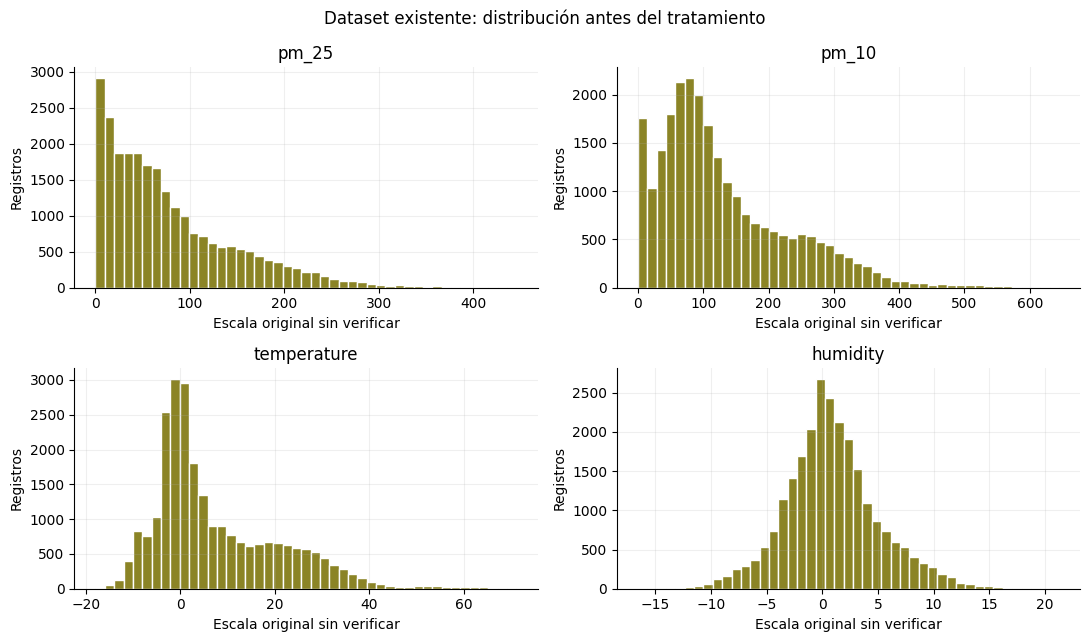

In [3]:
legacy = pd.read_csv(LEGACY)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for column, ax in zip(VARIABLES, axes.flat):
    ax.hist(legacy[column].dropna(), bins=45, color="#8b8426", edgecolor="white")
    ax.set(title=column, xlabel="Escala original sin verificar", ylabel="Registros")
fig.suptitle("Dataset existente: distribución antes del tratamiento")
fig.tight_layout()
fig.savefig(REPORTS / "legacy_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Fuentes y escala de observación

**Fuente principal: [RMCAB/SDA](https://rmcab.ambientebogota.gov.co/Report/HourlyReports)**.
Su [guía oficial](https://rmcab.ambientebogota.gov.co/home/text/1516) explica la
consulta y exportación de históricos. La disponibilidad cambia por estación y
variable. Un promedio anual interpolado no es una etiqueta horaria para entrenar
un pronóstico.

**Complemento opcional: [Open-Meteo/ERA5](https://open-meteo.com/en/docs/historical-weather-api)**
para temperatura, humedad, viento y precipitación. Es un reanálisis en rejilla:
se identifica como estimado y no como sensor de barrio. No se ha concatenado a
esta muestra. La API gratuita tiene condiciones de uso no comercial y atribución.

El [catálogo de estaciones](https://datosabiertos.bogota.gov.co/dataset/estaciones-calidad-del-aire-bogota-d-c)
puede apoyar la georreferenciación; no asumir que sus coordenadas actuales fueron
las mismas durante 2015–2025. No asignar el `station_id` del portal a un código
espacial del catálogo sin comprobar correspondencia e historial de reubicaciones.


In [4]:
contract = pd.DataFrame([
    {"campo": "datetime", "significado": "Hora final del intervalo publicado", "unidad": "America/Bogota"},
    {"campo": "station_id", "significado": "Estación, no ruta ni barrio", "unidad": "Identificador del portal"},
    *[{"campo": v, "significado": "Mismo nombre de variable que en el dashboard", "unidad": UNITS[v]} for v in VARIABLES],
    {"campo": "*_raw / *_origin / *_channel", "significado": "Valor original, tratamiento y sensor", "unidad": "Trazabilidad"},
    {"campo": "source_url / source_sha256", "significado": "Documento público de origen", "unidad": "Procedencia"},
])
display(contract)


,campo,significado,unidad
0,datetime,Hora final del intervalo publicado,America/Bogota
1,station_id,"Estación, no ruta ni barrio",Identificador del portal
2,pm_25,Mismo nombre de variable que en el dashboard,µg/m³
3,pm_10,Mismo nombre de variable que en el dashboard,µg/m³
4,temperature,Mismo nombre de variable que en el dashboard,°C
5,humidity,Mismo nombre de variable que en el dashboard,%
6,*_raw / *_origin / *_channel,"Valor original, tratamiento y sensor",Trazabilidad
7,source_url / source_sha256,Documento público de origen,Procedencia


## 3. Recolección y plan 2015–2025

La muestra incluye reportes de fechas concretas de varios años y una semana
continua de 2025. **No representa todos los meses ni estaciones del periodo.**
Los errores de descarga se registran; un error HTTP no equivale a una concentración
cero ni demuestra que no haya datos en otras fechas o exportaciones oficiales.

El recolector comprueba fecha, unidades y encabezados, rechaza cambios ambiguos y
guarda caché comprimida con SHA256. Selecciona `HR`; excluye `HR_2m` e instrumentos
internos para evitar mezclarlos sin armonización. Guarda la precisión que muestra
la tabla pública. Sus datos siguen con validación final no comprobada.

Para ampliar, ejecutar lotes mensuales con `research.collect_rmcab`. Para los once
años completos conviene obtener primero exportaciones masivas oficiales y adaptar
su esquema y sus banderas de calidad. No ejecutar miles de peticiones desde una
celda por defecto. Consultar `data/README.md` para los comandos.


In [5]:
months = pd.date_range(f"{START_YEAR}-01-01", f"{END_YEAR}-12-01", freq="MS")
collection_plan = pd.DataFrame({"start": months.strftime("%Y-%m-%d"),
    "end": (months + pd.offsets.MonthEnd()).strftime("%Y-%m-%d"), "status": "pending_full_collection"})
collection_plan["output"] = "data/processed/rmcab_" + months.strftime("%Y_%m") + ".csv"
collection_plan.to_csv(REPORTS / "collection_plan_2015_2025.csv", index=False, lineterminator="\n")
print(f"Objetivo: {START_YEAR}–{END_YEAR}; {len(collection_plan)} lotes mensuales. Estado: recolección completa pendiente.")
display(collection_plan.head(3))


Objetivo: 2015–2025; 132 lotes mensuales. Estado: recolección completa pendiente.


,start,end,status,output
0,2015-01-01,2015-01-31,pending_full_collection,data/processed/rmcab_2015_01.csv
1,2015-02-01,2015-02-28,pending_full_collection,data/processed/rmcab_2015_02.csv
2,2015-03-01,2015-03-31,pending_full_collection,data/processed/rmcab_2015_03.csv


In [6]:
SAMPLE = ROOT / "data/samples/rmcab_pilot_2015_2025.csv"
MANIFEST = SAMPLE.with_suffix(".sources.json")
source_manifest = json.loads(MANIFEST.read_text(encoding="utf-8"))
raw = pd.read_csv(SAMPLE, dtype={"station_id": "string"})
data = clean_measurements(raw)
assert not data.duplicated(["station_id", "datetime"]).any()
assert data.humidity.dropna().between(0, 100).all()
assert data.pm_25.dropna().ge(0).all() and data.pm_10.dropna().ge(0).all()
assert set(data.source_sha256) <= {entry["sha256"] for entry in source_manifest}
sample_digest = hashlib.sha256(SAMPLE.read_bytes()).hexdigest()
print(f"Muestra: {len(data):,} horas de estación publicadas; {len(source_manifest)} reportes descargados.")
display(data[["datetime", "station_name", *VARIABLES, "humidity_origin"]].head())
display(pd.DataFrame(source_manifest)[["report_date", "downloaded_at_utc", "sha256"]].head(3))


Muestra: 6,864 horas de estación publicadas; 17 reportes descargados.


,datetime,station_name,pm_25,pm_10,temperature,humidity,humidity_origin
0,2015-02-03 01:00:00-05:00,usaquen,6.4,8.3,12.5,NaN,missing
1,2015-02-03 01:00:00-05:00,suba,11.6,44.0,12.1,NaN,missing
2,2015-02-03 01:00:00-05:00,puente aranda,NaN,22.0,NaN,NaN,missing
3,2015-02-03 01:00:00-05:00,minambiente,10.3,17.8,NaN,NaN,missing
4,2015-02-03 01:00:00-05:00,san cristobal,2.3,5.0,10.8,71.0,observed


,report_date,downloaded_at_utc,sha256
0,2015-02-03,2026-10-23T13:29:44.588762+00:00,f4c965b7f5c775c56310ae3fce565ea5419d2dc0ed7a1e...
1,2016-02-03,2026-10-23T13:24:28.652491+00:00,d125206d65948f99e7c11221f07ebd96c79eccd9574abd...
2,2017-02-03,2026-10-23T13:24:34.810926+00:00,7b3887e0c702271293b68c9b0b107ec3a007eff3b8ea7e...


## 4. Cobertura real y exploración

El denominador `calendar_days` se refiere a cada año completo. `report_days`
solo cuenta fechas descargadas, no días con monitoreo completo. Las horas de
estación pueden contener valores ausentes. Las cuentas de observaciones se
muestran por variable. No sumar estas cifras como si fueran mediciones en barrios
independientes o inferir representatividad anual a partir de este piloto.


In [7]:
coverage = coverage_by_year(data).set_index("year").reindex(range(START_YEAR, END_YEAR + 1))
coverage.index.name = "year"
display(coverage)
coverage.to_csv(REPORTS / "pilot_coverage_by_year.csv", lineterminator="\n")
quality_counts = pd.DataFrame({v: data[f"{v}_origin"].value_counts() for v in VARIABLES}).fillna(0).astype(int)
display(quality_counts)


,report_days,calendar_days,sampled_calendar_pct,listed_stations,station_hours,pm_25_observed,pm_10_observed,temperature_observed,humidity_observed
year,,,,,,,,,
2015,1,365,0.27,12,288,203,262,168,144
2016,1,366,0.27,13,312,260,284,168,144
2017,1,365,0.27,13,312,286,284,168,168
2018,1,365,0.27,12,288,262,259,168,168
2019,1,365,0.27,14,336,285,312,216,192
2020,1,366,0.27,14,336,306,273,216,192
2021,1,365,0.27,18,432,400,383,310,206
2022,1,365,0.27,19,456,417,383,336,216
2023,1,365,0.27,19,456,378,372,311,238


,pm_25,pm_10,temperature,humidity
observed,5980,6019,4889,3731
missing,884,845,1975,3133


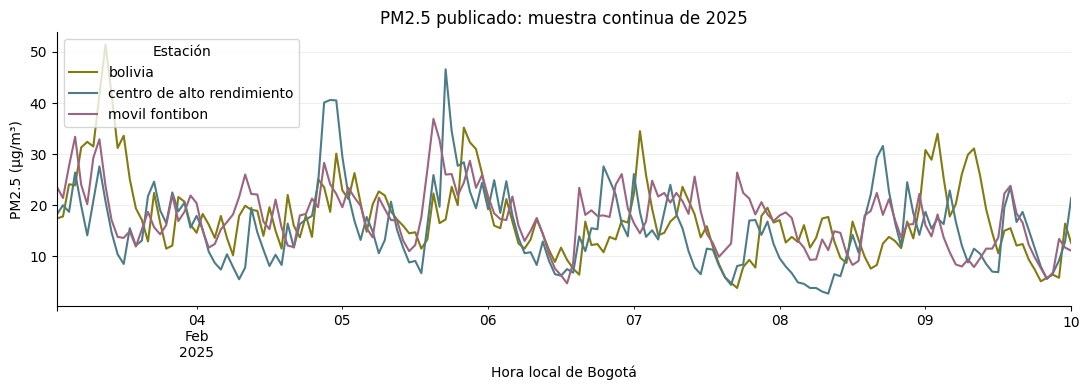

In [8]:
recent = data.loc[data.datetime.dt.year.eq(2025)]
station_order = recent.groupby("station_name").pm_25.count().nlargest(3).index
series = recent.loc[recent.station_name.isin(station_order)].pivot(index="datetime", columns="station_name", values="pm_25")
if not series.empty:
    hourly_index = pd.date_range(series.index.min(), series.index.max(), freq="h")
    series = series.reindex(hourly_index)  # Los huecos quedan visibles; no se interpolan.
    ax = series.plot(figsize=(11, 4), color=["#827b10", "#4d7c89", "#9b6481"])
    ax.set(title="PM2.5 publicado: muestra continua de 2025", xlabel="Hora local de Bogotá", ylabel="PM2.5 (µg/m³)")
    ax.legend(title="Estación", loc="upper left", ncol=1)
    plt.tight_layout()
    plt.savefig(REPORTS / "rmcab_pilot_pm25.png", dpi=150, bbox_inches="tight")
    plt.show()


## 5. Imputación de humedad con scikit-learn

Comparamos mediana y KNN con variables escaladas. Entrenamiento: reportes
anteriores a 2025. Validación: la muestra de 2025. Ocultamos aproximadamente el
25% de bloques estación/día/3 horas y evaluamos únicamente la humedad originalmente
conocida dentro de esos bloques. El escalador y los imputadores aprenden solo de
entrenamiento. No hay ajuste con las observaciones de validación.

Es un experimento **retrospectivo**, condicionado a covariables observadas en el
mismo momento; no mide precisión de un pronóstico. No prueba generalización a
estaciones nuevas, huecos de meses ni estacionalidad anual. Después se necesitan
más cortes temporales, estaciones retenidas y huecos de distintas duraciones.

MAE y RMSE se expresan en **puntos porcentuales de humedad**, no en porcentaje de
error relativo. El resultado no rellena automáticamente la tabla fuente. Véase
la [documentación de imputación](https://scikit-learn.org/stable/modules/impute.html)
y [fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).


In [9]:
imputation_scores, experiment = compare_humidity_imputers(data, cutoff="2025-01-01", seed=SEED)
display(imputation_scores)
display(pd.Series(experiment, name="Diseño del experimento").to_frame())
imputation_scores.to_csv(REPORTS / "humidity_imputation_scores.csv", index=False, lineterminator="\n")
(REPORTS / "humidity_imputation_experiment.json").write_text(json.dumps(experiment, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")


,method,MAE_percentage_points,RMSE_percentage_points,masked_values
0,Mediana,14.579047,16.857310,451
1,KNN escalado,16.494245,20.348505,451


,Diseño del experimento
status,research_only
train_rows,3672
validation_rows,3192
cutoff,2025-01-01T00:00:00-05:00
mask,25% of station/day/3-hour blocks; seed 42
limitation,Not station-held-out; historical pilot not a f...


296

## 6. Acoplar al modelo: observación, origen y objetivo

El repositorio no incluye un modelo entrenado guardado. Conservamos los nombres
`pm_25`, `pm_10`, `temperature`, `humidity` y definimos una tabla supervisada para
su implementación posterior. Cada fila conserva estación, hora y procedencia.

Para una proyección de 24 horas, `X(t)` usa mediciones disponibles en el origen,
rezagos exactos de 1/24 horas y calendario; `y(t+24h)` se obtiene de una observación
real en esa hora. **Los objetivos no se imputan.** No usar `shift(24)` sobre filas
irregulares: podría saltar de un año a otro. La meteorología futura observada en
un reanálisis tampoco es una entrada conocida al emitir un pronóstico.

La georreferenciación histórica e interpolación por barrio quedan para una etapa
posterior. Una estación no se convierte en cientos de muestras independientes por
replicar sus lecturas en distintos polígonos. Evaluar primero con estaciones
retenidas antes de mostrar valores estimados por barrio.


In [10]:
TARGET = "pm_25"
HORIZON_HOURS = 24  # También admite 1, 48 y 72; requiere etiquetas observadas en t+h.
candidate = build_forecast_table(data, target=TARGET, horizon_hours=HORIZON_HOURS)
FEATURES = [*VARIABLES, f"{TARGET}_lag_1h", f"{TARGET}_lag_24h", "hour_sin", "hour_cos", "month_sin", "month_cos", "weekday", "station_id"]
assert (candidate.target_datetime - candidate.datetime).eq(pd.Timedelta(hours=HORIZON_HOURS)).all()
assert candidate.target_value.notna().all()
display(candidate[["datetime", "station_name", "target_datetime", "target_value", f"{TARGET}_lag_1h", f"{TARGET}_lag_24h"]].head())
print(f"Filas candidatas con objetivo realmente observado: {len(candidate):,}. No es un modelo entrenado.")
candidate.to_csv(PROCESSED / f"forecast_candidate_{TARGET}_{HORIZON_HOURS}h.csv", index=False, lineterminator="\n")


,datetime,station_name,target_datetime,target_value,pm_25_lag_1h,pm_25_lag_24h
0,2025-02-03 01:00:00-05:00,suba,2025-02-04 01:00:00-05:00,24.0,NaN,NaN
1,2025-02-03 01:00:00-05:00,san cristobal,2025-02-04 01:00:00-05:00,8.0,NaN,NaN
2,2025-02-03 01:00:00-05:00,bolivia,2025-02-04 01:00:00-05:00,18.3,NaN,NaN
3,2025-02-03 01:00:00-05:00,fontibon,2025-02-04 01:00:00-05:00,17.3,NaN,NaN
4,2025-02-03 01:00:00-05:00,usme,2025-02-04 01:00:00-05:00,15.2,NaN,NaN


Filas candidatas con objetivo realmente observado: 2,472. No es un modelo entrenado.


In [11]:
split_report = []
if candidate.datetime.nunique() >= 8:
    for fold, (train_idx, valid_idx) in enumerate(purged_time_splits(candidate), 1):
        train, valid = candidate.iloc[train_idx], candidate.iloc[valid_idx]
        assert train.target_datetime.max() < valid.datetime.min()
        split_report.append({"fold": fold, "train_rows": len(train), "validation_rows": len(valid),
            "last_training_target": str(train.target_datetime.max()), "first_validation_origin": str(valid.datetime.min())})
display(pd.DataFrame(split_report))


,fold,train_rows,validation_rows,last_training_target,first_validation_origin
0,1,149,625,2025-02-04 12:00:00-05:00,2025-02-04 13:00:00-05:00
1,2,683,683,2025-02-06 00:00:00-05:00,2025-02-06 01:00:00-05:00
2,3,1339,678,2025-02-07 12:00:00-05:00,2025-02-07 13:00:00-05:00


## 7. Decisiones y siguientes experimentos

1. Completar y revisar los 132 meses; registrar qué estación/variable tiene
   mediciones válidas y cuándo cambió su instrumento o localización.
2. Homogeneizar escala y calibración del dataset original antes de incorporarlo.
3. Comparar mediana, KNN e imputación por estación/estación del año usando bloques
   de distintas duraciones. Aplicar solo donde la validación justifique el relleno,
   conservando un indicador de dato estimado y su método.
4. Entrenar un modelo base de persistencia y un regresor de scikit-learn con el
   mismo protocolo temporal; ajustar cualquier imputador dentro de cada `Pipeline`.
   Evaluar horizontes 24/48/72 por separado y dejar el último periodo sin tocar
   para la evaluación final. Este piloto no justifica afirmar buen rendimiento.
5. Evaluar generalización espacial y posteriormente interpolar por barrio con
   cobertura, fecha, método y error. La predicción no reemplaza una medición.

Las salidas del notebook permiten auditar el trabajo. No se cambian automáticamente
los CSV del dashboard ni se publica un modelo sin resultados contrastables.


In [12]:
assert hashlib.sha256(LEGACY.read_bytes()).hexdigest() == legacy_sha_before
run_manifest = {"legacy_sha256": legacy_sha_before, "pilot_sha256": sample_digest,
    "target_years": [START_YEAR, END_YEAR], "downloaded_reports": len(source_manifest),
    "pilot_only": True, "full_history_collected": False, "versions": versions, "random_seed": SEED,
    "forecast_model_trained": False, "legacy_dataset_modified": False}
(REPORTS / "run_manifest.json").write_text(json.dumps(run_manifest, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")
print("Notebook completado. Dataset original conservado; resultados y procedencia guardados en data/reports/.")


Notebook completado. Dataset original conservado; resultados y procedencia guardados en data/reports/.
